# EmojiHeroVR gameplay performance

Inspect whether recognition success improves over repeated presentations of the
same expression category during the recorded study session. This analysis investigates
possible adaptation to the in-game FER model.

**Unit of analysis:** one emoji reenactment. An emoji is successful if at least
one logged prediction matches its prompted category. Multiple predictions within
an emoji do not become separate reenactment outcomes. Success here denotes
compatibility with the deployed FER model, not independently verified expression
quality or the exact timing of awarded points.

Each participant completed **70 emojis: ten per category**. The main output is a
figure with seven category-specific curves. The analysis is descriptive: no
statistical tests or fitted learning curves are used.

Run all cells in order. The pinned Python/Jupyter environment and launch commands
are documented in `README.md`. 

In [2]:
from pathlib import Path
import hashlib
import importlib.metadata
import json
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import Markdown, display

CLASS_NAMES = ['Anger', 'Disgust', 'Fear', 'Happiness', 'Neutral', 'Sadness', 'Surprise']
KEYS = ['participant_id', 'level_id', 'emoji_id']
PROB_COLUMNS = [f'prob_{name.lower()}' for name in CLASS_NAMES]

# Run the notebook with its own directory as the working directory.
INPUT_PATH = Path('gameplay-logs.csv')
if not INPUT_PATH.exists():
        raise FileNotFoundError('No gameplay-logs.csv found in the current directory.')

FIGURE_DIR = Path('figures')
RESULT_DIR = Path('results')
FIGURE_DIR.mkdir(exist_ok=True)
RESULT_DIR.mkdir(exist_ok=True)

versions = {'Python': platform.python_version()}
versions.update({name: importlib.metadata.version(name)
                 for name in ['numpy', 'pandas', 'matplotlib', 'jupyterlab']})
display(pd.Series(versions, name='Version').to_frame())


,Version
Python,3.14.8
numpy,2.5.4
pandas,3.0.6
matplotlib,3.11.2
jupyterlab,4.6.4


## 1. Load and validate the log

Check category names, probability ranges, outcome flags and completeness of the
fixed study sequence before aggregation. Retain failed/invalid requests as
non-matching records. Do not remove repeated timestamps or identical-looking
rows: these may be distinct requests, and their validity cannot be decided from
rounded probabilities and timestamps alone.

Reenactments are ordered by **level and emoji ID**, not by timestamp. This avoids
relying on the unusable timestamps for one participant. No latency estimates are
made. Only aggregate diagnostics are displayed.


In [4]:
logs = pd.read_csv(INPUT_PATH, dtype={
    'participant_id': 'int64', 'level_id': 'int64', 'emoji_id': 'int64',
    'timestamp_unix_ms': 'int64',
    'target_expression': 'string', 'predicted_expression': 'string',
})

logs.head(n=10)


,participant_id,level_id,emoji_id,timestamp_unix_ms,target_expression,predicted_expression,prob_anger,prob_disgust,prob_fear,prob_happiness,prob_neutral,prob_sadness,prob_surprise,prediction_matches_target,emoji_success
0,1,1,0,1700478995309,Anger,Anger,0.50,0.16,0.00,0.01,0.14,0.17,0.02,True,True
1,1,1,0,1700478995614,Anger,Anger,0.51,0.06,0.01,0.01,0.23,0.17,0.01,True,True
2,1,1,0,1700478995947,Anger,Anger,0.49,0.10,0.01,0.01,0.17,0.21,0.02,True,True
3,1,1,0,1700478996240,Anger,Neutral,0.26,0.01,0.03,0.03,0.46,0.20,0.02,False,True
4,1,1,0,1700478996544,Anger,Sadness,0.29,0.01,0.02,0.02,0.30,0.35,0.02,False,True
5,1,1,1,1700478997812,Sadness,Disgust,0.02,0.82,0.03,0.00,0.01,0.12,0.00,False,True
6,1,1,1,1700478998104,Sadness,Disgust,0.03,0.68,0.02,0.00,0.01,0.26,0.00,False,True
7,1,1,1,1700478998442,Sadness,Sadness,0.04,0.05,0.04,0.00,0.02,0.84,0.01,True,True
8,1,1,1,1700478998743,Sadness,Sadness,0.05,0.23,0.02,0.00,0.02,0.67,0.01,True,True
9,1,1,1,1700478999007,Sadness,Sadness,0.03,0.03,0.01,0.00,0.01,0.91,0.01,True,True


In [5]:
required = set(KEYS + PROB_COLUMNS + [
    'timestamp_unix_ms', 'target_expression', 'predicted_expression',
    'prediction_matches_target', 'emoji_success',
])
missing_columns = required.difference(logs.columns)
if missing_columns:
    raise ValueError(f'Missing columns: {sorted(missing_columns)}')

def parse_boolean(values, name):
    parsed = values.astype('string').str.strip().str.lower().map({'true': True, 'false': False})
    if parsed.isna().any():
        raise ValueError(f'{name} contains missing or invalid boolean values.')
    return parsed.astype(bool)

for name in ['prediction_matches_target', 'emoji_success']:
    logs[name] = parse_boolean(logs[name], name)

if logs.empty or logs[KEYS + ['target_expression']].isna().any().any():
    raise ValueError('The log is empty or has missing identifiers/targets.')
if not logs['target_expression'].isin(CLASS_NAMES).all():
    raise ValueError('Unknown target expression.')
if not logs['predicted_expression'].dropna().isin(CLASS_NAMES).all():
    raise ValueError('Unknown predicted expression.')

probabilities = logs[PROB_COLUMNS].apply(pd.to_numeric, errors='raise')
if not np.isfinite(probabilities.to_numpy()).all():
    raise ValueError('Non-finite probabilities.')
if not probabilities.ge(0).all().all() or not probabilities.le(1).all().all():
    raise ValueError('Probabilities must be between zero and one.')

zero_probability = probabilities.eq(0).all(axis=1)
missing_prediction = logs['predicted_expression'].isna()
if not zero_probability.equals(missing_prediction):
    raise ValueError('Missing predictions and all-zero probability records do not agree.')

# Keep the recorded class: probabilities are rounded, so a new argmax can change ties.
logs['valid_prediction'] = ~missing_prediction
logs['matches_target'] = logs['predicted_expression'].eq(logs['target_expression']).fillna(False)
if not logs['matches_target'].equals(logs['prediction_matches_target'].astype('boolean')):
    # Compare values explicitly because pandas boolean storage dtypes can differ.
    if not np.array_equal(logs['matches_target'].to_numpy(dtype=bool),
                          logs['prediction_matches_target'].to_numpy(dtype=bool)):
        raise ValueError('prediction_matches_target disagrees with the recorded classes.')

grouped = logs.groupby(KEYS, sort=True)
if not grouped['target_expression'].nunique().eq(1).all():
    raise ValueError('An emoji has multiple target categories.')
if not grouped['emoji_success'].nunique().eq(1).all():
    raise ValueError('emoji_success changes within an emoji.')
any_match = grouped['matches_target'].any()
if not np.array_equal(any_match.to_numpy(dtype=bool),
                      grouped['emoji_success'].first().to_numpy(dtype=bool)):
    raise ValueError('emoji_success disagrees with at least one matching prediction.')

participant_timestamps = logs.groupby('participant_id')['timestamp_unix_ms'].nunique()
quality_counts = {
    'Logged FER records': len(logs),
    'Participants': logs['participant_id'].nunique(),
    'Emoji reenactments': len(grouped),
    'Records without a valid prediction': int(missing_prediction.sum()),
    'Participants with constant timestamps': int(participant_timestamps.eq(1).sum()),
    'Repeated key-and-timestamp rows beyond the first': int(logs.duplicated(KEYS + ['timestamp_unix_ms']).sum()),
    'Fully identical rows beyond the first': int(logs.drop(columns=['valid_prediction', 'matches_target']).duplicated().sum()),
}
display(pd.Series(quality_counts, name='Count').to_frame())
print('All records are retained. Supplied matching and emoji-success flags are consistent.')

,Count
Logged FER records,20482
Participants,37
Emoji reenactments,2590
Records without a valid prediction,71
Participants with constant timestamps,1
Repeated key-and-timestamp rows beyond the first,253
Fully identical rows beyond the first,2


All records are retained. Supplied matching and emoji-success flags are consistent.


## 2. Count success once per emoji

Collapse all FER records belonging to the same participant, level and emoji into
one binary outcome. A failed/invalid request does not match the target; an emoji
with other matching records still succeeds. Every participant contributes one
outcome at each presentation number for each category.

The study sequence has 9, 12, 21 and 28 emojis in Levels 1–4. Anger, happiness and
sadness first appear in Level 1; the other categories first appear in Level 2.
Every category has three presentations in its introductory level, three in
Level 3 and four in Level 4. Thus, category presentation numbers 1–3, 4–6 and
7–10 correspond to those three stages.


In [7]:
emojis = grouped.agg(
    target_expression=('target_expression', 'first'),
    success=('matches_target', 'any'),
    n_predictions=('matches_target', 'size'),
    n_valid_predictions=('valid_prediction', 'sum'),
).reset_index().sort_values(KEYS).reset_index(drop=True)
emojis['n_invalid_predictions'] = emojis['n_predictions'] - emojis['n_valid_predictions']
emojis['category_presentation'] = emojis.groupby(
    ['participant_id', 'target_expression'], sort=False
).cumcount() + 1
emojis['session_emoji_number'] = emojis.groupby('participant_id', sort=False).cumcount() + 1
n_participants = emojis['participant_id'].nunique()

expected_level_sizes = {1: 9, 2: 12, 3: 21, 4: 28}
for (_, level), block in emojis.groupby(['participant_id', 'level_id']):
    if level not in expected_level_sizes or sorted(block['emoji_id']) != list(range(expected_level_sizes[level])):
        raise ValueError('Incomplete or unexpected emoji sequence within a level.')
if not emojis.groupby('participant_id').size().eq(70).all():
    raise ValueError('Expected 70 emojis per participant.')
if not emojis.groupby(['participant_id', 'target_expression']).size().eq(10).all():
    raise ValueError('Expected ten presentations per participant and category.')
if emojis.groupby(['level_id', 'emoji_id'])['target_expression'].nunique().gt(1).any():
    raise ValueError('The fixed target sequence differs between participants.')

first_level = {'Anger': 1, 'Disgust': 2, 'Fear': 2, 'Happiness': 1,
               'Neutral': 2, 'Sadness': 1, 'Surprise': 2}
expected_level = np.where(
    emojis['category_presentation'].le(3), emojis['target_expression'].map(first_level),
    np.where(emojis['category_presentation'].le(6), 3, 4),
)
if not np.array_equal(emojis['level_id'], expected_level):
    raise ValueError('Category repetitions do not follow the expected level stages.')

total_success = int(emojis['success'].sum())
print(f'{n_participants} participants × 70 emojis = {len(emojis):,} reenactments.')
print(f'{total_success:,}/{len(emojis):,} emojis had at least one matching prediction '
      f'({emojis["success"].mean():.2%}).')

emojis.head(n=10)

37 participants × 70 emojis = 2,590 reenactments.
1,747/2,590 emojis had at least one matching prediction (67.45%).


,participant_id,level_id,emoji_id,target_expression,success,n_predictions,n_valid_predictions,n_invalid_predictions,category_presentation,session_emoji_number
0,1,1,0,Anger,True,5,5,0,1,1
1,1,1,1,Sadness,True,5,5,0,1,2
2,1,1,2,Happiness,True,5,5,0,1,3
3,1,1,3,Anger,True,5,5,0,2,4
4,1,1,4,Anger,True,5,5,0,3,5
5,1,1,5,Sadness,False,5,5,0,2,6
6,1,1,6,Happiness,True,5,5,0,2,7
7,1,1,7,Sadness,True,5,5,0,3,8
8,1,1,8,Happiness,True,5,5,0,3,9
9,1,2,0,Neutral,True,5,5,0,1,10


## 3. Recognition success by expression and presentation

For category $c$ at presentation $r$, the plotted value is

$$100\times\frac{\text{participants with at least one matching prediction for }(c,r)}
                     {\text{participants with that presentation}}.$$

The denominator is 37 at every point for the supplied complete study log.
No point is weighted by the number of predictions or by the duration of the
recording window. The exported table includes successful counts and denominators.


In [8]:
by_presentation = emojis.groupby(
    ['target_expression', 'category_presentation'], sort=True
).agg(
    n_successful=('success', 'sum'),
    n_emojis=('success', 'size'),
    n_participants=('participant_id', 'nunique'),
    level_id=('level_id', 'first'),
).reset_index()
by_presentation['success_rate_pct'] = 100 * by_presentation['n_successful'] / by_presentation['n_emojis']
if len(by_presentation) != 70 or not by_presentation['n_participants'].eq(n_participants).all():
    raise ValueError('Expected ten points per category with the same participant denominator.')
if not by_presentation['n_emojis'].eq(n_participants).all():
    raise ValueError('A participant contributes more than once to a plotted point.')

presentation_rates = by_presentation.pivot(
    index='target_expression', columns='category_presentation', values='success_rate_pct'
).reindex(CLASS_NAMES)
display(presentation_rates.style.format('{:.1f}').set_caption('Recognition success (%) by category presentation'))


category_presentation,1,2,3,4,5,6,7,8,9,10
target_expression,,,,,,,,,,
Anger,45.9,32.4,35.1,29.7,29.7,40.5,24.3,27.0,18.9,32.4
Disgust,62.2,54.1,51.4,56.8,64.9,73.0,56.8,59.5,54.1,48.6
Fear,40.5,29.7,32.4,35.1,35.1,32.4,35.1,32.4,35.1,27.0
Happiness,100.0,94.6,94.6,94.6,86.5,100.0,97.3,89.2,89.2,81.1
Neutral,97.3,97.3,97.3,100.0,97.3,97.3,94.6,100.0,97.3,91.9
Sadness,59.5,62.2,64.9,70.3,70.3,62.2,64.9,64.9,75.7,67.6
Surprise,91.9,94.6,97.3,91.9,94.6,94.6,97.3,89.2,89.2,89.2


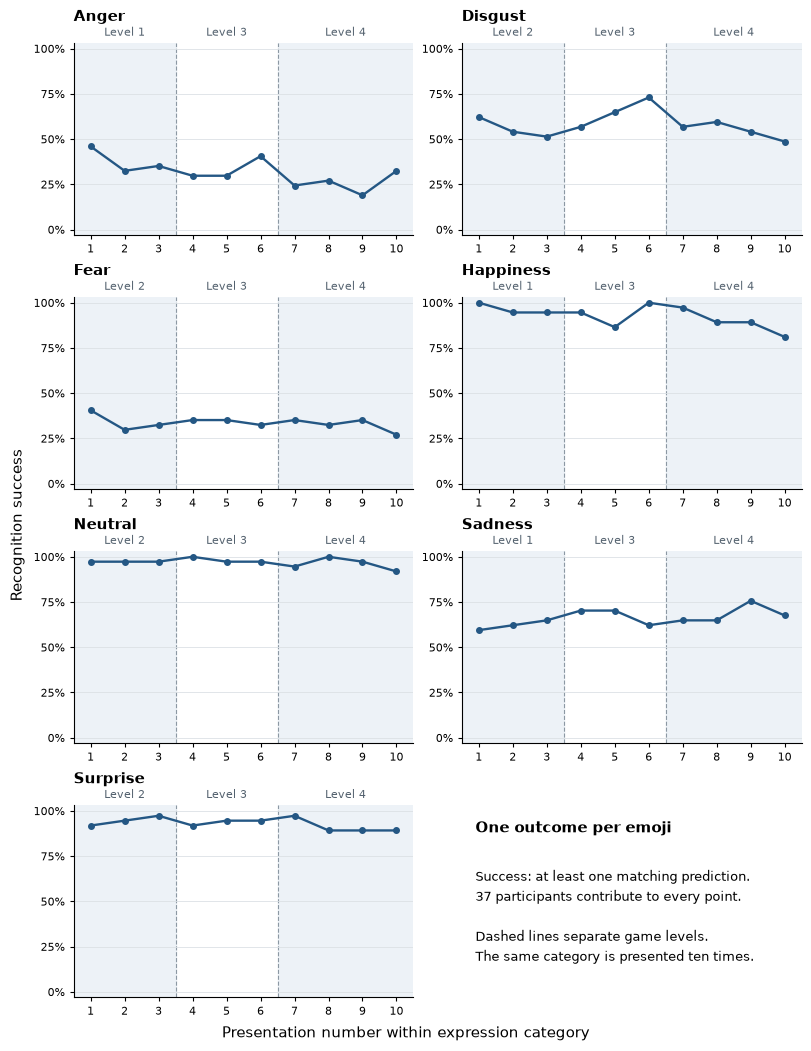

Saved the combined PDF/PNG and seven separate vector PDFs in figures/.


In [9]:
PLOT_STYLE = {
    'font.family': 'DejaVu Sans', 'font.size': 9,
    'axes.titlesize': 11, 'axes.labelsize': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'pdf.fonttype': 42, 'savefig.dpi': 300,
}
LINE_COLOUR = '#245784'

def draw_category(ax, expression):
    values = by_presentation.loc[by_presentation['target_expression'].eq(expression)]
    ax.axvspan(0.5, 3.5, color='#edf2f7', zorder=0)
    ax.axvspan(6.5, 10.5, color='#edf2f7', zorder=0)
    for boundary in [3.5, 6.5]:
        ax.axvline(boundary, color='#8c98a3', linestyle='--', linewidth=0.8, zorder=1)
    ax.plot(values['category_presentation'], values['success_rate_pct'],
            color=LINE_COLOUR, marker='o', markersize=4, linewidth=1.7, zorder=3)
    ax.set_title(expression, loc='left', fontweight='bold', pad=16)
    ax.set_xlim(0.5, 10.5)
    ax.set_ylim(-3, 103)
    ax.set_xticks(range(1, 11))
    ax.set_yticks(range(0, 101, 25))
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
    ax.grid(axis='y', color='#dce1e5', linewidth=0.6, zorder=0)
    ax.tick_params(labelsize=8, length=3)
    for x, label in [(2, f'Level {first_level[expression]}'), (5, 'Level 3'), (8.5, 'Level 4')]:
        ax.text(x, 1.025, label, transform=ax.get_xaxis_transform(),
                ha='center', va='bottom', fontsize=8, color='#53616e')

pdf_metadata = {'Title': 'EmojiHeroVR recognition success',
                'Creator': 'Matplotlib', 'CreationDate': None, 'ModDate': None}
with plt.rc_context(PLOT_STYLE):
    figure, axes = plt.subplots(4, 2, figsize=(8.0, 10.4), sharex=True, sharey=True,
                                layout='constrained')
    for expression, ax in zip(CLASS_NAMES, axes.flat):
        draw_category(ax, expression)
        ax.tick_params(labelbottom=True, labelleft=True)
    note = axes.flat[-1]
    note.set_axis_off()
    note.text(0.04, 0.86, 'One outcome per emoji', fontsize=11, fontweight='bold', transform=note.transAxes)
    note.text(0.04, 0.68,
              'Success: at least one matching prediction.\n'
              f'{n_participants} participants contribute to every point.\n\n'
              'Dashed lines separate game levels.\n'
              'The same category is presented ten times.',
              fontsize=9, linespacing=1.6, va='top', transform=note.transAxes)
    figure.supxlabel('Presentation number within expression category', fontsize=11)
    figure.supylabel('Recognition success', fontsize=11)
    figure.savefig(FIGURE_DIR / 'gameplay_success_by_expression.pdf', metadata=pdf_metadata)
    figure.savefig(FIGURE_DIR / 'gameplay_success_by_expression.png', dpi=220)
    plt.show()
    plt.close(figure)

    # Separate vector PDFs can also be arranged directly in LaTeX.
    for expression in CLASS_NAMES:
        figure, ax = plt.subplots(figsize=(5.0, 3.25), layout='constrained')
        draw_category(ax, expression)
        ax.set_xlabel('Presentation number within category')
        ax.set_ylabel('Recognition success')
        figure.savefig(FIGURE_DIR / f'gameplay_success_{expression.lower()}.pdf', metadata=pdf_metadata)
        plt.close(figure)

print('Saved the combined PDF/PNG and seven separate vector PDFs in figures/.')


## 4. Descriptive summary

Report overall success and compare the first three with the last three
presentations of each category. Averaging three presentations reduces reliance
on a single endpoint. The final comparison uses presentations **8–10**, not all
four presentations in Level 4.

This is a concise description of early and late observed performance. It is
**not** a difficulty-adjusted learning estimate: the two blocks occurred in
different levels, with different speeds and recognition opportunities. No
confidence intervals or significance claims are attached to this comparison.


In [10]:
by_expression = emojis.groupby('target_expression').agg(
    n_emojis=('success', 'size'), n_successful=('success', 'sum')
).reindex(CLASS_NAMES)
by_expression['success_rate_pct'] = 100 * by_expression['n_successful'] / by_expression['n_emojis']
early = emojis.loc[emojis['category_presentation'].le(3)].groupby('target_expression')['success'].mean()
late = emojis.loc[emojis['category_presentation'].ge(8)].groupby('target_expression')['success'].mean()
by_expression['first_three_success_pct'] = 100 * early
by_expression['last_three_success_pct'] = 100 * late
by_expression['change_pp'] = 100 * (late - early)
display(by_expression.style.format({
    'n_emojis': '{:,.0f}', 'n_successful': '{:,.0f}',
    'success_rate_pct': '{:.2f}', 'first_three_success_pct': '{:.2f}',
    'last_three_success_pct': '{:.2f}', 'change_pp': '{:+.2f}',
}).set_caption('Emoji-level recognition success (%); early–late difference in percentage points'))

increased = by_expression.index[by_expression['change_pp'].gt(0)].tolist()
decreased = by_expression.index[by_expression['change_pp'].lt(0)].tolist()
description = (
    f'In the first-three versus last-three comparison, success is higher for '
    f'**{len(increased)} of {len(CLASS_NAMES)} categories**'
    + (f' ({", ".join(increased).lower()})' if increased else '')
    + f' and lower for **{len(decreased)} categories**. '
    'These differences describe the observed curves; they are not significance tests.'
)
display(Markdown(description))


,n_emojis,n_successful,success_rate_pct,first_three_success_pct,last_three_success_pct,change_pp
target_expression,,,,,,
Anger,370,117,31.62,37.84,26.13,-11.71
Disgust,370,215,58.11,55.86,54.05,-1.80
Fear,370,124,33.51,34.23,31.53,-2.70
Happiness,370,343,92.70,96.40,86.49,-9.91
Neutral,370,359,97.03,97.30,96.40,-0.90
Sadness,370,245,66.22,62.16,69.37,+7.21
Surprise,370,344,92.97,94.59,89.19,-5.41


In the first-three versus last-three comparison, success is higher for **1 of 7 categories** (sadness) and lower for **6 categories**. These differences describe the observed curves; they are not significance tests.

## 5. Context for interpretation and reproducibility

The table below gives level-level context, not an additional learning analysis.
The number of logged predictions is broadly similar in Levels 1–3 and lower in
Level 4 for the supplied data. More recognition opportunities can increase the
chance of at least one matching prediction.

The mean recording-window durations shown here are taken from **thesis Section
5.7, Table “Overview of the data recorded during the user study”**. They are not
computed from this prediction log. The recording window includes a preceding
buffer and is not identical to the interval eligible for gameplay recognition.

FER sampling also varies between participants. Because the same participants
contribute at every category presentation, the curves do not change their
participant composition; changing level conditions still constrain interpretation.


In [11]:
by_level = emojis.groupby('level_id').agg(
    n_emojis=('success', 'size'), n_successful=('success', 'sum'),
    mean_logged_predictions=('n_predictions', 'mean'),
    mean_valid_predictions=('n_valid_predictions', 'mean'),
    invalid_predictions=('n_invalid_predictions', 'sum'),
)
by_level['success_rate_pct'] = 100 * by_level['n_successful'] / by_level['n_emojis']
# Contextual values from the thesis; not an estimate from timestamps in this file.
by_level['mean_recording_window_s_thesis'] = pd.Series({1: 2.14, 2: 2.14, 3: 2.00, 4: 1.61})
display(by_level.style.format({
    'n_emojis': '{:,.0f}', 'n_successful': '{:,.0f}', 'invalid_predictions': '{:,.0f}',
    'mean_logged_predictions': '{:.2f}', 'mean_valid_predictions': '{:.2f}',
    'success_rate_pct': '{:.2f}', 'mean_recording_window_s_thesis': '{:.2f}',
}))

by_presentation.to_csv(RESULT_DIR / 'success_by_presentation.csv', index=False, float_format='%.8f')
by_expression.to_csv(RESULT_DIR / 'success_by_expression.csv', float_format='%.8f')
by_level.to_csv(RESULT_DIR / 'success_by_level.csv', float_format='%.8f')
metadata = {
    'input_file': INPUT_PATH.as_posix(),
    'input_sha256': hashlib.sha256(INPUT_PATH.read_bytes()).hexdigest(),
    'requirements_sha256': hashlib.sha256(Path('requirements.txt').read_bytes()).hexdigest(),
    'outcome': 'At least one logged prediction matches the prompted expression per participant-level-emoji.',
    'ordering': 'level_id, then emoji_id; category presentation counts continue across levels.',
    'versions': versions,
    'quality_counts': {name: int(value) for name, value in quality_counts.items()},
    'successful_emojis': total_success,
    'total_emojis': len(emojis),
    'overall_success_pct': float(100 * emojis['success'].mean()),
    'recording_window_duration_source': 'Thesis Section 5.7, collected-data overview table.',
    'formal_statistical_tests': False,
}
(RESULT_DIR / 'analysis_metadata.json').write_text(json.dumps(metadata, indent=2) + '\n', encoding='utf-8')
print('Saved three aggregate CSV tables and analysis_metadata.json in results/.')


,n_emojis,n_successful,mean_logged_predictions,mean_valid_predictions,invalid_predictions,success_rate_pct,mean_recording_window_s_thesis
level_id,,,,,,,
1,333,218,8.75,8.71,16,65.47,2.14
2,444,313,8.74,8.70,17,70.50,2.14
3,777,539,8.74,8.72,13,69.37,2.00
4,"1,036",677,6.65,6.63,25,65.35,1.61


Saved three aggregate CSV tables and analysis_metadata.json in results/.


## Interpretation for the thesis correction

For the supplied study log, the category-specific curves do not show a consistent
increase in recognition success across categories. Sadness has a higher success
rate in the last three than in the first three presentations; the other categories
have lower rates. Several categories already have high initial success, leaving
limited scope for improvement. The displayed changes are descriptive and do not
establish statistical significance.

Shorter windows, fewer prediction opportunities in the faster final level, fixed
ordering, and expression training and game familiarisation before recording
limit what can be inferred about learning. The appropriate conclusion is that
**no consistent improvement in recognition success was observed during the recorded
session**, rather than that participants did not adapt to the FER model.

Recognition performance alone does not measure the variety of facial movements.
Recognition-based rewards may still have discouraged difficult-to-recognise
expression variants, including before the analysed session. Separate manual
annotation can assess recorded expressions, but cannot recover variants that
participants did not produce.
